# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理


In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244081104

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

print(f"numpy {np.__version__} / scipy {scipy.__version__} / "
      f"matplotlib {matplotlib.__version__} / pandas {pd.__version__}")


[Conda 环境] pytorch
[学号]       20244081104
[机器指纹] 90bdc247d63f884e
[RUN_ID]   20244081104-90bdc247d63f884e
numpy 2.1.2 / scipy 1.17.1 / matplotlib 3.10.8 / pandas 3.0.1


## 1. NumPy 数组、数据类型与索引


### 1.1 三种 dtype 的数组


In [2]:
a_int = np.array([1, 2, 3, 4])
a_float = np.array([1.5, 2.5, 3.5, 4.5])
a_bool = np.array([True, False, True, False])

for name, arr in [("整数", a_int), ("浮点", a_float), ("布尔", a_bool)]:
    print(f"{name}: dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")

print("整数的 itemsize:", a_int.dtype.itemsize, "字节")
print("浮点的 itemsize:", a_float.dtype.itemsize, "字节")
print("布尔的 itemsize:", a_bool.dtype.itemsize, "字节")


整数: dtype=int64, shape=(4,), ndim=1
浮点: dtype=float64, shape=(4,), ndim=1
布尔: dtype=bool, shape=(4,), ndim=1
整数的 itemsize: 8 字节
浮点的 itemsize: 8 字节
布尔的 itemsize: 1 字节


解释：NumPy 数组的数据类型与 Python 列表的差别

Python 列表只保存元素的指针，同一个列表里可以混放整数、浮点和字符串，所以没有"整体类型"这回事。NumPy 数组则要求全部元素是同一个 dtype，在内存里连续存放固定长度的字节，上面 `itemsize` 输出就是每种 dtype 占的字节数：整数和浮点都是 8 字节（int64 / float64），布尔只要 1 字节。正因为同质且连续，数组才能整体参与向量化运算，代价是混合类型时会被统一向上转换（例如把整数和浮点放进同一个数组，整数会被提升成浮点），精度和类型不受你控制。


### 1.2 arange 改形状


In [3]:
base = np.arange(12)
print("原数组:", base, "shape =", base.shape)

m34 = base.reshape(3, 4)
m232 = base.reshape(2, 3, 2)

print("\nreshape(3, 4):")
print(m34)
print("shape =", m34.shape, "ndim =", m34.ndim)

print("\nreshape(2, 3, 2):")
print(m232)
print("shape =", m232.shape, "ndim =", m232.ndim)

print("\n元素总数:", base.size, "=", m34.size, "=", m232.size)


原数组: [ 0  1  2  3  4  5  6  7  8  9 10 11] shape = (12,)

reshape(3, 4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape = (3, 4) ndim = 2

reshape(2, 3, 2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
shape = (2, 3, 2) ndim = 3

元素总数: 12 = 12 = 12


说明：改变形状时元素总数必须满足什么条件

新形状各维度的乘积必须等于原数组的元素个数（这里是 12）。`3×4=12`、`2×3×2=12` 都成立，所以 reshape 成功；如果写成 `reshape(5, 3)`（需要 15 个元素）NumPy 会抛 `ValueError: cannot reshape array of size 12 into shape (5,3)`。reshape 并不移动数据，只是换一种索引方式，因此元素个数必须守恒；某一维写 `-1` 时，NumPy 会自动推导出该维大小。


### 1.3 三种索引


In [4]:
print("矩阵 m34:")
print(m34)

row2 = m34[1]
print("\n取第 2 行  m34[1] = ", row2, "  shape =", row2.shape)

cols13 = m34[:, 0:3]
print("\n取第 1 至第 3 列  m34[:, 0:3] =")
print(cols13)
print("shape =", cols13.shape)

big = m34[m34 > 6]
print("\n取大于 6 的元素  m34[m34 > 6] = ", big, "  shape =", big.shape)


矩阵 m34:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第 2 行  m34[1] =  [4 5 6 7]   shape = (4,)

取第 1 至第 3 列  m34[:, 0:3] =
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
shape = (3, 3)

取大于 6 的元素  m34[m34 > 6] =  [ 7  8  9 10 11]   shape = (5,)


注意三种索引得到的形状并不一样：取一行得到一维 `(4,)`（维数从 2 降到 1），取列切片仍是二维 `(3, 3)`，而布尔索引 `m34[m34 > 6]` 会把命中的元素拉平成一维 `(5,)`，丢掉了原来的行列位置信息。如果既想筛选又保留二维结构，应改用 `np.where` 或先用掩码再按行处理。


### 1.4 布尔运算的两个条件


In [5]:
arr = np.arange(10)
print("arr =", arr)

lt2_or_gt7 = arr[(arr < 2) | (arr > 7)]
print("小于 2 或大于 7:", lt2_or_gt7)

gt3_and_lt7 = arr[(arr > 3) & (arr < 7)]
print("大于 3 且小于 7:", gt3_and_lt7)

print("用 np.logical_or 等价:", arr[np.logical_or(arr < 2, arr > 7)])
print("用 np.logical_and 等价:", arr[np.logical_and(arr > 3, arr < 7)])


arr = [0 1 2 3 4 5 6 7 8 9]
小于 2 或大于 7: [0 1 8 9]
大于 3 且小于 7: [4 5 6]
用 np.logical_or 等价: [0 1 8 9]
用 np.logical_and 等价: [4 5 6]


组合条件时括号不能省。`&`、`|` 的优先级高于比较运算符，写成 `arr > 3 & arr < 7` 会被解析成 `arr > (3 & arr) < 7`，报 `ValueError: The truth value of an array with more than one element is ambiguous`。另外这里必须用按位的 `&`、`|`，不能用 Python 的 `and`、`or`，因为后者会对整个数组求真假值，同样触发上面的错误。


### 1.5 逐元素乘法与矩阵乘法


In [6]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A =")
print(A)
print("B =")
print(B)

print("\nA * B  (逐元素):")
print(A * B)

print("\nnp.multiply(A, B):")
print(np.multiply(A, B))

print("\nA @ B  (矩阵乘法):")
print(A @ B)

print("\nnp.matmul(A, B):")
print(np.matmul(A, B))

print("\n两种结果是否相同:", np.array_equal(A * B, A @ B))


A =
[[1 2]
 [3 4]]
B =
[[5 6]
 [7 8]]

A * B  (逐元素):
[[ 5 12]
 [21 32]]

np.multiply(A, B):
[[ 5 12]
 [21 32]]

A @ B  (矩阵乘法):
[[19 22]
 [43 50]]

np.matmul(A, B):
[[19 22]
 [43 50]]

两种结果是否相同: False


说明：逐元素乘法与矩阵乘法的区别

`*` 和 `np.multiply()` 是逐元素乘法（Hadamard 积），要求两个数组形状相同或可广播，结果仍是同样形状：这里 `[[1,2],[3,4]] * [[5,6],[7,8]] = [[5,12],[21,32]]`，位置一一对应相乘。`@` 和 `np.matmul()` 是线性代数意义的矩阵乘法，要求左矩阵的列数等于右矩阵的行数，结果形状由"行×列"决定：这里 `(2,2)@(2,2)` 仍是 `(2,2)`，第一行第一列 `1×5+2×7=19`。所以两者算出来的数完全不同，`np.array_equal` 返回 `False`。如果误用 `*` 做矩阵乘法，在方阵上不会报错，会安静地给出错误结果，这是最常见的坑。


## 2. 随机抽样、统计与缺失值


### 2.1 模拟成绩与 np.clip


In [7]:
np.random.seed(2024)

raw_scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(raw_scores, 0, 100)

print(f"样本数   : {scores.size}")
print(f"最小值   : {scores.min():.4f}")
print(f"最大值   : {scores.max():.4f}")
print(f"均值     : {scores.mean():.4f}")
print(f"标准差   : {scores.std():.4f}")
print(f"极差     : {scores.max() - scores.min():.4f}")

clipped = int((raw_scores != scores).sum())
print(f"\n被 clip 截断的样本: {clipped} 个 "
      f"(>100 的 {int((raw_scores > 100).sum())} 个, <0 的 {int((raw_scores < 0).sum())} 个)")
print(f"截断前均值 {raw_scores.mean():.4f} / 标准差 {raw_scores.std():.4f}")


样本数   : 1000
最小值   : 33.2710
最大值   : 100.0000
均值     : 70.2335
标准差   : 10.1270
极差     : 66.7290

被 clip 截断的样本: 2 个 (>100 的 2 个, <0 的 0 个)
截断前均值 70.2400 / 标准差 10.1477


解释：模拟成绩的统计量与 np.clip 的作用

`np.random.seed(2024)` 保证结果可复现。`np.clip` 把超出 [0, 100] 的样本压到边界上，本样本有 2 个超过 100 的观测值被截断，所以截断后均值从 70.2400 变成 70.2335、标准差从 10.1477 降到 10.1270——截断会把极值拉到边界，分布因此变窄。正态分布本身是无界的，理论上一定会有落在 [0, 100] 之外的样本，`np.clip` 正是用来把"不可能的成绩"拉回合理区间的。


### 2.2 不放回抽样：均匀 vs 按大小加权


In [8]:
np.random.seed(7)
pop = np.arange(1, 11)
print("总体:", pop)

uniform_sample = np.random.choice(pop, size=5, replace=False)
print("均匀抽样:", uniform_sample)

weights = pop / pop.sum()
print("\n权重 (与数值大小成正比):")
print(np.round(weights, 4))
print("权重和 =", weights.sum())

np.random.seed(7)
weighted_sample = np.random.choice(pop, size=5, replace=False, p=weights)
print("\n加权抽样:", weighted_sample)


总体: [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样: [9 6 1 3 2]

权重 (与数值大小成正比):
[0.0182 0.0364 0.0545 0.0727 0.0909 0.1091 0.1273 0.1455 0.1636 0.1818]
权重和 = 1.0

加权抽样: [ 3  9  7 10  6]


两种写法只差一个 `p` 参数：不传 `p` 时，总体的每个元素被抽中的概率相同；传 `p` 时按给定的概率分布抽，`p` 的和必须等于 1，否则抛 `ValueError: probabilities do not sum to 1`。这里把权重设成与数值大小成正比，大数被抽中的机会明显更高，所以加权样本 `[3 9 7 10 6]` 整体比均匀样本 `[9 6 1 3 2]` 偏大。`replace=False` 表示不放回，因此数组长度不能超过总体大小。


### 2.3 随机排列：保留原数组 vs 原地打乱


In [9]:
a = np.arange(10)
print("原始 a      :", a)

np.random.seed(11)
shuffled_copy = np.random.permutation(a)
print("permutation 后:", shuffled_copy)
print("原数组 a     :", a)

print("-" * 40)

b = np.arange(10)
b_before = b.copy()
print("原始 b      :", b_before)

np.random.seed(11)
ret = np.random.shuffle(b)
print("shuffle 的返回值:", ret)
print("打乱后 b    :", b)
print("b_before 还在吗:", b_before)


原始 a      : [0 1 2 3 4 5 6 7 8 9]
permutation 后: [7 8 2 6 4 5 1 3 0 9]
原数组 a     : [0 1 2 3 4 5 6 7 8 9]
----------------------------------------
原始 b      : [0 1 2 3 4 5 6 7 8 9]
shuffle 的返回值: None
打乱后 b    : [7 8 2 6 4 5 1 3 0 9]
b_before 还在吗: [0 1 2 3 4 5 6 7 8 9]


`np.random.permutation(a)` 返回打乱后的新数组，原数组 `a` 不变；`np.random.shuffle(b)` 则原地打乱 `b`，并且返回 `None`。正因为 `shuffle` 会直接改掉传入的数组，想知道打乱前长什么样，必须在调用之前先 `b.copy()` 留一份，上面的输出里 `b_before` 仍然是 `[0 1 2 ... 9]` 就是这个原因。两者共用同一个随机数流，所以在同一个种子下打乱结果完全一致。


### 2.4 nan 对统计函数的影响


In [10]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan

print("第 10、20、30 个位置:", scores_nan[[9, 19, 29]])
print("缺失值个数:", int(np.isnan(scores_nan).sum()))

print(f"\nnp.mean   : {np.mean(scores_nan)}")
print(f"np.nanmean: {np.nanmean(scores_nan):.4f}")
print(f"np.sum    : {np.sum(scores_nan)}")
print(f"np.nansum : {np.nansum(scores_nan):.4f}")
print(f"np.std    : {np.std(scores_nan)}")
print(f"np.nanstd : {np.nanstd(scores_nan):.4f}")
print(f"\n有效样本数: {int((~np.isnan(scores_nan)).sum())}")


第 10、20、30 个位置: [nan nan nan]
缺失值个数: 3

np.mean   : nan
np.nanmean: 70.2344
np.sum    : nan
np.nansum : 70023.7442
np.std    : nan
np.nanstd : 10.1373

有效样本数: 997


说明：nan 对普通统计函数的影响

`nan` 参与任何算术运算的结果仍然是 `nan`，而 `np.mean`、`np.sum`、`np.std` 这类普通聚合函数默认"整条数据都算"，只要出现一个 `nan`，结果就整个变成 `nan`。所以这里 `np.mean(scores_nan)` 和 `np.std(scores_nan)` 都输出 `nan`。带 `nan` 前缀的版本（`np.nanmean`、`np.nansum`、`np.nanstd`）会先跳过缺失值、只对 997 个有效样本统计，得到 70.2344、70023.7442、10.1373。需要注意的是跳过并不等于没有影响：有效样本从 1000 降到 997，统计量的抽样波动会略大一点，而且 `nan` 还会让 `nan == nan` 返回 `False`，判断缺失只能用 `np.isnan`。


### 2.5 整理成表格变量（供实验4使用）


In [11]:
score_table = pd.DataFrame({
    "序号": np.arange(1, 1001),
    "成绩": scores_nan,
})

print(score_table.head(8))
print("...")
print(f"\n形状: {score_table.shape}")
print(f"缺失值: {int(score_table['成绩'].isna().sum())} 个")
print("\ndescribe():")
print(score_table["成绩"].describe())


   序号         成绩
0   1  86.680473
1   2  77.373477
2   3  67.984622
3   4  68.490881
4   5  79.160518
5   6  81.603296
6   7  43.800380
7   8  56.747054
...

形状: (1000, 2)
缺失值: 3 个

describe():
count    997.000000
mean      70.234448
std       10.142351
min       33.271003
25%       63.425831
50%       70.102950
75%       77.276691
max      100.000000
Name: 成绩, dtype: float64


这份数据只保留在内存变量 `score_table` 里，没有写入磁盘，供后面的实验使用。`describe()` 的 `count` 是 997 而不是 1000，同样印证了缺失值被自动跳过。


## 3. SciPy 数值计算与 Matplotlib 可视化


### 3.1 线性方程组


In [12]:
from scipy import linalg

A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([9.0, 8.0])

x = linalg.solve(A, b)
print("解 x =", x)
print(f"即 x = {x[0]:.6f}, y = {x[1]:.6f}")

check = A @ x
print("\n代回验证 A @ x =", check)
print("与 b 是否一致（用 allclose）:", np.allclose(check, b))
print("用 == 逐个比较:", check == b)
print("最大绝对误差:", np.abs(check - b).max())


解 x = [2. 3.]
即 x = 2.000000, y = 3.000000

代回验证 A @ x = [9. 8.]
与 b 是否一致（用 allclose）: True
用 == 逐个比较: [False  True]
最大绝对误差: 1.7763568394002505e-15


解是 `x = 2, y = 3`。代回验证时 `np.allclose` 返回 `True`，但 `==` 逐个比较却是 `[False True]`：浮点数在二进制下无法精确表示，`3×2+1×3` 的计算结果是 `8.999999999999998` 而非精确的 `9`，最大绝对误差约 `1.78e-15`。所以判断浮点相等一定要用 `np.allclose`，不能直接 `==`。


### 3.2 用 root 求根


In [13]:
from scipy import optimize

def f(x):
    return x**2 - 2

root_pos = optimize.root(f, x0=1.0)
print("正根:")
print(f"  成功: {root_pos.success}, 状态码: {root_pos.status}")
print(f"  x = {root_pos.x[0]:.10f}")
print(f"  f(x) = {f(root_pos.x[0]):.3e}")

root_neg = optimize.root(f, x0=-1.0)
print("\n负根:")
print(f"  成功: {root_neg.success}, 状态码: {root_neg.status}")
print(f"  x = {root_neg.x[0]:.10f}")
print(f"  f(x) = {f(root_neg.x[0]):.3e}")

print(f"\n解析解 sqrt(2) = {2**0.5:.10f}, -sqrt(2) = {-(2**0.5):.10f}")


正根:
  成功: True, 状态码: 1
  x = 1.4142135624
  f(x) = -8.882e-16

负根:
  成功: True, 状态码: 1
  x = -1.4142135624
  f(x) = -8.882e-16

解析解 sqrt(2) = 1.4142135624, -sqrt(2) = -1.4142135624


同样一个方程有两个根，`scipy.optimize.root` 是局部迭代法，只能找到离初始猜测值最近的那个根：`x0=1.0` 收敛到 `+1.4142135624`，`x0=-1.0` 收敛到 `-1.4142135624`，两者的 `f(x)` 都是 `-8.882e-16` 量级，可以认为等于 0。如果初值给在 0 附近，由于该点导数为 0，还可能不收敛，所以初值的选择很关键。


### 3.3 用 minimize 求极小值


In [14]:
def g(x):
    return x**2 + x + 2

res = optimize.minimize(g, x0=0.0)
print(f"成功: {res.success}")
print(f"极小点 x = {res.x[0]:.10f}")
print(f"极小值 f(x) = {res.fun:.10f}")
print(f"迭代次数: {res.nit}, 函数调用次数: {res.nfev}")

print(f"\n解析解: x = -b/(2a) = {-1 / 2:.10f}")
print(f"          f(-0.5) = {(-0.5)**2 + (-0.5) + 2:.10f}")
print(f"\n与解析解的差值: {abs(res.x[0] - (-0.5)):.3e}")


成功: True
极小点 x = -0.5000000064
极小值 f(x) = 1.7500000000
迭代次数: 2, 函数调用次数: 8

解析解: x = -b/(2a) = -0.5000000000
          f(-0.5) = 1.7500000000

与解析解的差值: 6.435e-09


对二次函数 `f(x)=x²+x+2`，顶点在 `x = -b/(2a) = -0.5`，极小值 `f(-0.5) = 1.75`。数值解给出 `x = -0.5000000064`，与解析解相差约 `6.4e-09`，函数值 `1.75` 完全一致。用 BFGS 这类拟牛顿法只迭代了 2 次就收敛，因为二次函数的梯度和海森矩阵是常数，一步就能确定方向；剩余误差来自收敛容差（默认 `gtol=1e-5`），把容差调小可以再精确一些。


### 3.4 独立样本 t 检验


In [15]:
from scipy import stats

np.random.seed(42)
group1 = np.random.normal(loc=0, scale=1, size=100)
group2 = np.random.normal(loc=1, scale=1, size=100)

print(f"第一组: 均值 {group1.mean():.4f}, 标准差 {group1.std(ddof=1):.4f}, n={group1.size}")
print(f"第二组: 均值 {group2.mean():.4f}, 标准差 {group2.std(ddof=1):.4f}, n={group2.size}")

t_stat, p_value = stats.ttest_ind(group1, group2)
print(f"\nt 统计量 = {t_stat:.6f}")
print(f"p 值     = {p_value:.3e}")

alpha = 0.05
if p_value < alpha:
    print(f"\np = {p_value:.3e} < {alpha}，拒绝原假设：两组均值存在显著差异。")
else:
    print(f"\np = {p_value:.3e} >= {alpha}，不能拒绝原假设：没有足够证据说明两组均值不同。")


第一组: 均值 -0.1038, 标准差 0.9082, n=100
第二组: 均值 1.0223, 标准差 0.9537, n=100

t 统计量 = -8.551460
p 值     = 3.293e-15

p = 3.293e-15 < 0.05，拒绝原假设：两组均值存在显著差异。


原假设 H0 是"两组均值相等"。这里 `t = -8.551460`、`p = 3.293e-15`，p 值远小于 0.05，拒绝 H0，两组均值存在显著差异，与生成数据时设定的均值差（0 vs 1）一致。p 值表示"H0 为真时，观察到这么极端结果的概率"，它不是"两组相等的概率"，也不衡量差异的绝对大小；t 为负只说明第一组均值更小。


### 3.5 Matplotlib 可视化


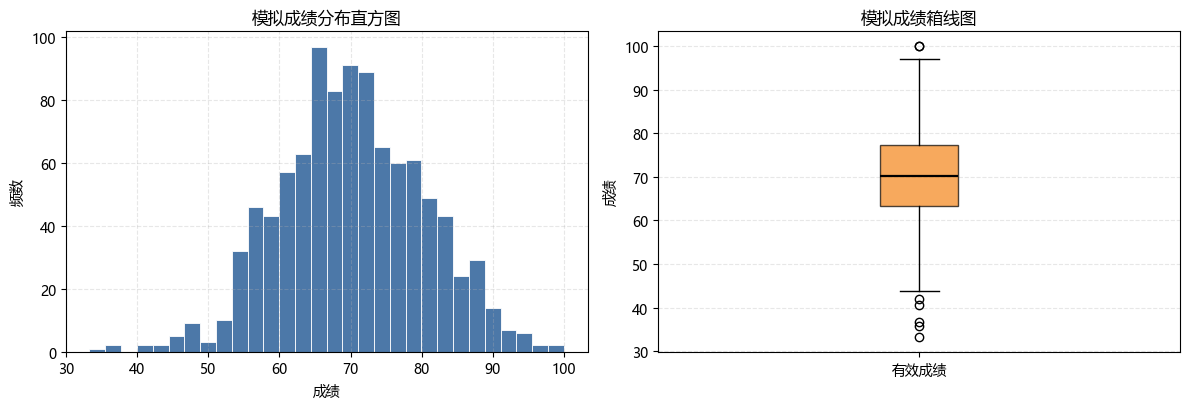

参与绘图的样本数: 997
四分位数 Q1=63.43, 中位数=70.10, Q3=77.28


In [16]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

valid_scores = scores_nan[~np.isnan(scores_nan)]

axes[0].hist(valid_scores, bins=30, color="#4C78A8", edgecolor="white", linewidth=0.6)
axes[0].set_title("模拟成绩分布直方图")
axes[0].set_xlabel("成绩")
axes[0].set_ylabel("频数")
axes[0].grid(alpha=0.3, linestyle="--")

axes[1].boxplot(valid_scores, vert=True, patch_artist=True,
                boxprops=dict(facecolor="#F58518", alpha=0.7),
                medianprops=dict(color="black", linewidth=1.6))
axes[1].set_title("模拟成绩箱线图")
axes[1].set_ylabel("成绩")
axes[1].set_xticklabels(["有效成绩"])
axes[1].grid(alpha=0.3, linestyle="--", axis="y")

plt.tight_layout()
plt.show()

print(f"参与绘图的样本数: {valid_scores.size}")
print(f"四分位数 Q1={np.percentile(valid_scores, 25):.2f}, "
      f"中位数={np.median(valid_scores):.2f}, Q3={np.percentile(valid_scores, 75):.2f}")


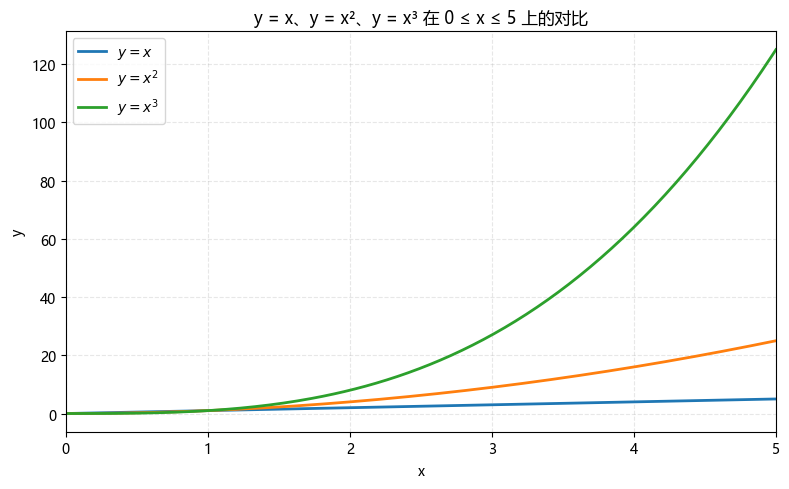

在 x=5 处三个函数的值:
  y = x: 5.0
  y = x^2: 25.0
  y = x^3: 125.0


In [17]:
fig2, ax = plt.subplots(figsize=(8, 5))

xs = np.linspace(0, 5, 200)
ax.plot(xs, xs, label=r"$y = x$", linewidth=2)
ax.plot(xs, xs**2, label=r"$y = x^2$", linewidth=2)
ax.plot(xs, xs**3, label=r"$y = x^3$", linewidth=2)

ax.set_title("y = x、y = x²、y = x³ 在 0 ≤ x ≤ 5 上的对比")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, linestyle="--")
ax.set_xlim(0, 5)

plt.tight_layout()
plt.show()

print("在 x=5 处三个函数的值:")
for name, val in [("x", 5.0), ("x^2", 25.0), ("x^3", 125.0)]:
    print(f"  y = {name}: {val:.1f}")


直方图与箱线图都用剔除 nan 之后的 997 个有效成绩绘制（`valid_scores`），否则 matplotlib 会因为 `nan` 报错或位置错乱。直方图显示成绩大致呈钟形、集中在 60~85；箱线图的箱体从 Q1=63.43 到 Q3=77.28、中位数 70.10，与实验 2 的均值 70.23 吻合，上下两端的圆点是离群值，来自正态分布的尾部。折线图上三条曲线在 x 较小时贴得很近，x 越大差距越快拉开：`x=5` 时分别是 5、25、125，这正是三次方增长远快于线性增长的直观体现。


## 4. pandas Series、DataFrame 与内存中的 CSV 读写


### 4.1 创建 DataFrame 并计算总分、平均分


In [18]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")

SUBJECTS = ["Math", "English", "Python"]
df["Total"] = df[SUBJECTS].sum(axis=1)
df["Average"] = df[SUBJECTS].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名  :", df.columns.tolist())
print("\n前 3 行:")
print(df.head(3))
print("\n基本统计信息:")
print(df.describe())


行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名  : ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


行索引是姓名，列名里 `Group` 是字符串，其余 Math/English/Python/Total/Average 都是数值。计算 Total 和 Average 时必须先选出三科再聚合（`df[SUBJECTS]`），否则 pandas 会把 `Group` 字符串列一起卷进来：`sum(axis=1)` 会因为字符串和数字没法相加而抛 `TypeError`。`describe()` 只统计数值列，字符串列被自动跳过，所以输出里没有 `Group`。


### 4.2 loc 与 iloc 取 Carol，并筛选平均分 ≥ 80


In [19]:
print("loc['Carol']  (按标签):")
print(df.loc["Carol"])

carol_pos = df.index.get_loc("Carol")
print(f"\nCarol 的位置是 {carol_pos}，iloc[{carol_pos}] (按位置):")
print(df.iloc[carol_pos])

print("\n两者是否完全相同:", df.loc["Carol"].equals(df.iloc[carol_pos]))

print("\n平均分 >= 80 的学生:")
high = df[df["Average"] >= 80]
print(high[["Group", "Total", "Average"]])
print(f"\n人数: {len(high)} 人 -> {high.index.tolist()}")


loc['Carol']  (按标签):
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

Carol 的位置是 2，iloc[2] (按位置):
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

两者是否完全相同: True

平均分 >= 80 的学生:
      Group  Total    Average
Name                         
Alice     A    273  91.000000
Carol     B    265  88.333333
Eva       A    257  85.666667
Frank     B    243  81.000000

人数: 4 人 -> ['Alice', 'Carol', 'Eva', 'Frank']


`loc` 按标签取，`iloc` 按整数位置取。Carol 的行索引标签是字符串 `"Carol"`，所以 `df.loc["Carol"]` 能取到；要在 `iloc` 里写对位置，先用 `df.index.get_loc("Carol")` 查出它在第 2 行（0 基），再 `df.iloc[2]`。两者取到的是同一行（`equals` 返回 `True`），区别只在传参的含义：`loc` 的编号包含切片末端，`iloc` 不包含。平均分 ≥ 80 的学生共 4 人：Alice 91.00、Carol 88.33、Eva 85.67、Frank 81.00。


### 4.3 mean(axis=0) 与 mean(axis=1)


In [20]:
col_mean = df[SUBJECTS].mean(axis=0)
print("每科的列均值 (axis=0):")
print(col_mean)

row_mean = df[SUBJECTS].mean(axis=1)
print("\n每名学生的行均值 (axis=1):")
print(row_mean)

print("\n两者是否和 Average 列一致:", np.allclose(row_mean.values, df["Average"].values))

print("\n注意——如果对整个 df 直接 mean(axis=1):")
print(df.mean(axis=1, numeric_only=True))


每科的列均值 (axis=0):
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生的行均值 (axis=1):
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64

两者是否和 Average 列一致: True

注意——如果对整个 df 直接 mean(axis=1):
Name
Alice    127.400000
Bob      102.666667
Carol    123.666667
David     97.066667
Eva      119.933333
Frank    113.400000
dtype: float64


`axis=0` 沿行方向压缩、得到每列的均值（三个科目各一个数）；`axis=1` 沿列方向压缩、得到每行的均值（每个学生一个数），结果与 4.1 算出的 `Average` 列完全一致。容易踩的坑是直接对整张表调 `mean(axis=1)`：那样会把 `Total` 和 `Average` 也当成一列参与平均，Alice 会算成 `(88+90+95+273+91)/5 = 127.4`，而不是 `(88+90+95)/3 = 91.0`。上面最后一段演示的就是这个错误结果，所以必须先 `df[SUBJECTS]` 选好列再聚合。


### 4.4 apply、agg 与 rank


In [21]:
df["Best"] = df[SUBJECTS].apply(lambda row: max(row), axis=1)
print("每人三科最高分:")
print(df[["Math", "English", "Python", "Best"]])

print("\n用 agg() 一次拿到每科的最小/均值/最大:")
agg_result = df[SUBJECTS].agg(["min", "mean", "max"])
print(agg_result.round(2))

print("\n按 Math 排名（分数高的名次靠前）:")
df["Math_rank"] = df["Math"].rank(ascending=False, method="min").astype(int)
print(df[["Math", "Math_rank"]].sort_values("Math_rank"))


每人三科最高分:
       Math  English  Python  Best
Name                              
Alice    88       90      95    95
Bob      72       68      80    80
Carol    91       85      89    91
David    65       73      70    73
Eva      79       92      86    92
Frank    84       77      82    84

用 agg() 一次拿到每科的最小/均值/最大:
       Math  English  Python
min   65.00    68.00   70.00
mean  79.83    80.83   83.67
max   91.00    92.00   95.00

按 Math 排名（分数高的名次靠前）:
       Math  Math_rank
Name                  
Carol    91          1
Alice    88          2
Frank    84          3
Eva      79          4
Bob      72          5
David    65          6


`apply(..., axis=1)` 是按行逐条调用函数，所以 `lambda row: max(row)` 得到的是每个学生的三科最高分；`axis=0`（默认）则是按列调用，语义完全不同。`agg(["min","mean","max"])` 一次传入多个聚合函数，输出的行是函数名、列是科目，一次就拿到全部 9 个统计量。`rank()` 默认是升序排名，分数最低的名次为 1，所以这里必须加上 `ascending=False`，高分才排在前面。本例数学成绩没有重复值，名次正好是 1 到 6。


### 4.5 分组统计与 transform


In [22]:
grouped = df.groupby("Group")

print("每组人数:")
print(grouped.size())

print("\n每组三科平均分:")
print(grouped[SUBJECTS].mean().round(2))

df["GroupPythonMean"] = grouped["Python"].transform("mean")
print("\ntransform('mean') 为每行加上所在组的 Python 均分:")
print(df[["Group", "Python", "GroupPythonMean"]])


每组人数:
Group
A    3
B    3
dtype: int64

每组三科平均分:
        Math  English  Python
Group                        
A      79.67    83.33   87.00
B      80.00    78.33   80.33

transform('mean') 为每行加上所在组的 Python 均分:
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


A 组 3 人（Alice、Bob、Eva），B 组 3 人（Carol、David、Frank）。`groupby().mean()` 把每组压缩成一行，结果索引是组名；`transform("mean")` 则把每组的统计量按原行广播回去，行数和行索引都与原表一致，所以能直接赋值成新列 `GroupPythonMean`。A 组 Python 均分 87.0、B 组 80.33，Alice/Bob/Eva 三行都填 87.0。


### 4.6 filter 保留 Python 均分 ≥ 80 的组


In [23]:
# 题目说的"Python 均分"，先按学生筛（等价于用 transform 算的组内均分）
student_mean = grouped["Python"].transform("mean")
df["GroupPythonMean"] = student_mean
above = df[df["GroupPythonMean"] >= 80]
print("按学生筛（Python 所在的组均分 >= 80）:")
print(above[["Group", "Python", "GroupPythonMean"]])

# 题目点名要用的 filter()：保留 Python 均分 >= 80 的组
kept = grouped.filter(lambda g: g["Python"].mean() >= 80)
print("\nfilter() 保留的组和学生:")
print(kept[["Group", "Python", "Average"]])

print(f"\n保留的行数: {len(kept)} / {len(df)}")
print("保留的组:", sorted(kept["Group"].unique().tolist()))

print("\n各组 Python 均分:")
print(grouped["Python"].mean().round(4))


按学生筛（Python 所在的组均分 >= 80）:
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333

filter() 保留的组和学生:
      Group  Python    Average
Name                          
Alice     A      95  91.000000
Bob       A      80  73.333333
Carol     B      89  88.333333
David     B      70  69.333333
Eva       A      86  85.666667
Frank     B      82  81.000000

保留的行数: 6 / 6
保留的组: ['A', 'B']

各组 Python 均分:
Group
A    87.0000
B    80.3333
Name: Python, dtype: float64


说明：这里"均分"指的是什么

题目要求"使用 `filter` 保留 Python 均分 ≥ 80 的组"，所以 `filter` 里的判断对象是整组的 Python 均值，不是每个学生自己的 Python 分数，也不是三科总平均分。`filter()` 传给回调函数的是子 DataFrame，回调返回 True 就把这一组的所有行原样保留。

按这个口径算：A 组 Python 均分 `(95+80+86)/3 = 87.00`，B 组 `(89+70+82)/3 = 80.33`，两组都 ≥ 80，因此 `filter()` 返回全部 6 行。上面第一段用 `transform("mean")` 把组均分广播回每一行，是为了直观地看到每个学生所在组的均分；第二段才是题目点名要用的 `filter()` 写法。如果换成三科总均分来判断，B 组会降到 79.89 而被筛掉，这是这一题最容易出错的地方。


### 4.7 协方差矩阵与相关系数矩阵


In [24]:
cov_mx = df[SUBJECTS].cov()
corr_mx = df[SUBJECTS].corr()

print("协方差矩阵:")
print(cov_mx.round(4))

print("\n皮尔逊相关系数矩阵:")
print(corr_mx.round(4))

print("\n对角线:", np.diag(corr_mx.values).round(6))

pair = ("Math", "Python")
print(f"\nMath 与 Python: 协方差 = {cov_mx.loc[pair]:.4f}, 相关系数 = {corr_mx.loc[pair]:.4f}")


协方差矩阵:
            Math  English   Python
Math     98.1667  62.5667  74.9333
English  62.5667  93.3667  62.5333
Python   74.9333  62.5333  73.0667

皮尔逊相关系数矩阵:
           Math  English  Python
Math     1.0000   0.6535  0.8848
English  0.6535   1.0000  0.7571
Python   0.8848   0.7571  1.0000

对角线: [1. 1. 1.]

Math 与 Python: 协方差 = 74.9333, 相关系数 = 0.8848


解释：协方差符号与相关系数大小的含义（以 Math 与 Python 为例）

Math 与 Python 的协方差是 74.93，符号为正，表示两科成绩同向变化——数学分高的学生，Python 分往往也高；协方差的对角线是各自的方差（Math 98.17、English 93.37、Python 73.07）。但协方差的数值大小带单位，把成绩从百分制换成 0~1 的小数，协方差会缩到万分之一，所以它只能看符号、不能跨变量比较强弱。皮尔逊相关系数把协方差除以两个标准差的乘积，得到无量纲的数值：`r = 74.93 / (√98.17 × √73.07) = 0.8848`，取值范围固定在 [-1, 1]，绝对值越大线性关系越强。0.8848 说明 Math 和 Python 之间有很强的正线性相关；English 与 Math 是 0.6535、与 Python 是 0.7571，正相关但明显弱一些。需要注意：相关不等于因果，而且这里只有 6 个样本，相关系数的抽样波动很大，不能当成稳定的总体规律。
